# Credit Card Fraud Detection — Baseline Model Comparison

## Objective
This notebook establishes a **baseline performance benchmark** by training three standard machine
learning models directly on the **raw, imbalanced dataset** — without any over-sampling or data
augmentation. This serves as the control experiment to highlight:

1. How poorly standard models behave on severely skewed data.
2. The need for techniques such as SMOTE (explored in `math_model.ipynb`).

**Models evaluated:**
- Linear Regression (adapted for classification via 0.5 threshold)
- Logistic Regression
- Random Forest Classifier

---

## Dataset
The `creditcard.csv` dataset contains **284,807** European credit card transactions from September 2013,
of which only **492 (0.172%)** are fraudulent. Features `V1`–`V28` are PCA-transformed components;
`Time`, `Amount`, and `Class` remain in their original form.

## Cell 1 — Imports
We load all necessary libraries. No balancing or augmentation library is used — this is a pure baseline run.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report,
    precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, matthews_corrcoef, accuracy_score
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 12, "figure.dpi": 150})

os.makedirs("graphs", exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Libraries loaded. Baseline experiment — NO balancing applied.")

Libraries loaded. Baseline experiment — NO balancing applied.


## Cell 2 — Load Dataset & Apply Feature Selection

The same **12 selected features** identified during the feature selection phase are used here for
fair comparison across all notebooks in this project:

$$\mathcal{F} = \{V_2, V_3, V_4, V_7, V_9, V_{10}, V_{11}, V_{12}, V_{14}, V_{16}, V_{17}, V_{18}\}$$

These features were selected based on their high correlation with the fraud class and their
strong discriminative importance in permutation-based feature ranking.

In [2]:
file_path = r"C:\abishek js\ML-Projects (3rd year)\Credit-Card_Fraud_detection\creditcard.csv"

df = pd.read_csv(file_path)

# 12 features from feature selection
selected_features = ['V10', 'V11', 'V12', 'V14', 'V16', 'V17', 'V18',
                     'V2', 'V3', 'V4', 'V7', 'V9']

X = df[selected_features].values
y = df['Class'].values

n_total = len(y)
n_legit = int(np.sum(y == 0))
n_fraud = int(np.sum(y == 1))

print(f"Dataset loaded — {n_total:,} transactions, {X.shape[1]} selected features")
print(f"Legitimate (0) : {n_legit:,}   ({n_legit/n_total*100:.4f}%)")
print(f"Fraud      (1) : {n_fraud:,}     ({n_fraud/n_total*100:.4f}%)")

Dataset loaded — 284,807 transactions, 12 selected features
Legitimate (0) : 284,315   (99.8273%)
Fraud      (1) : 492     (0.1727%)


## Cell 3 — Class Distribution Visualisation

Visualising the raw class imbalance before any model is trained.

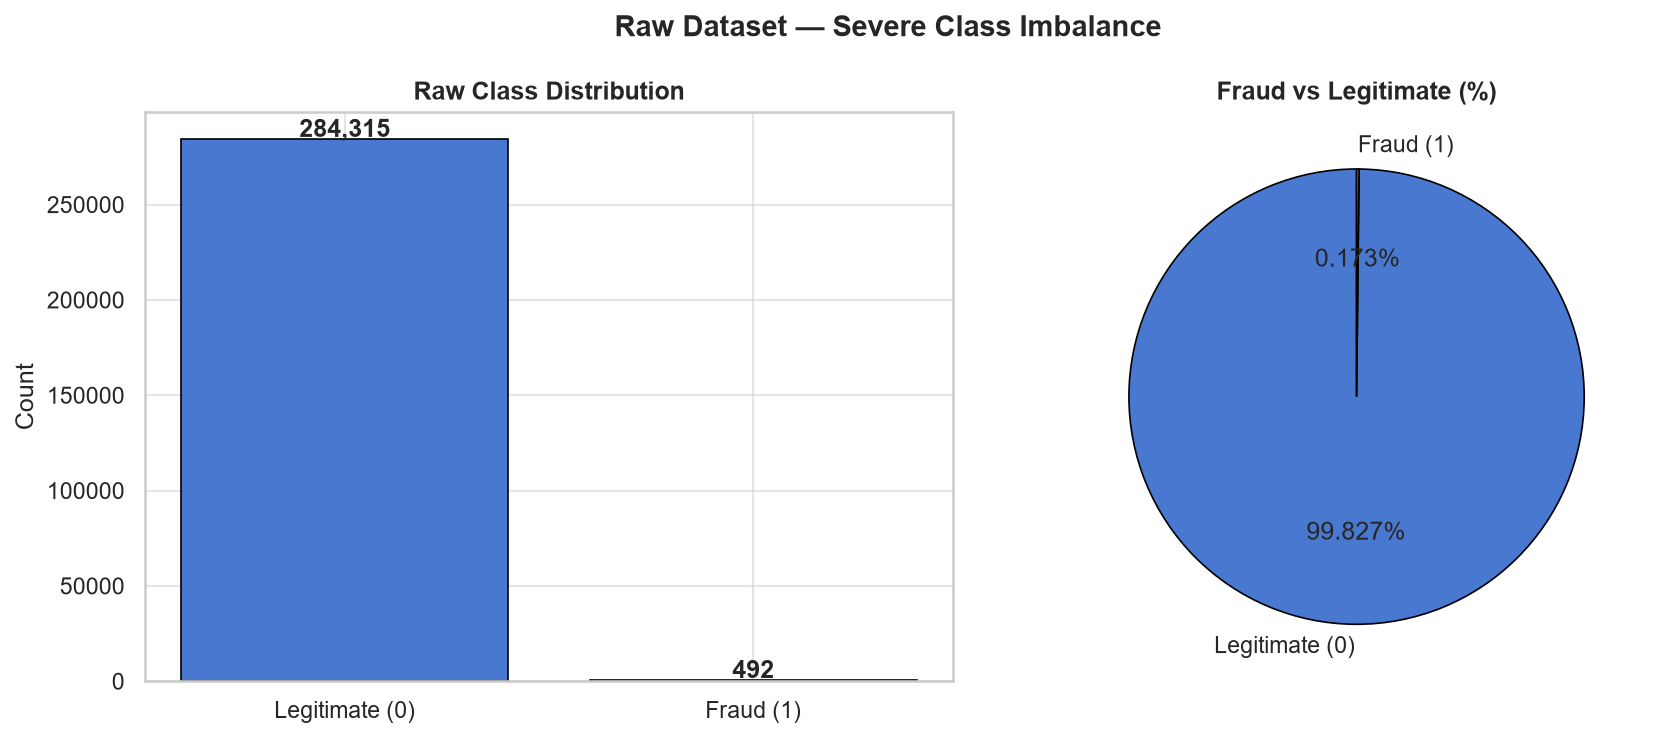

Chart saved -> graphs/b01_class_distribution.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

counts = [n_legit, n_fraud]
labels = ['Legitimate (0)', 'Fraud (1)']
colors = ['#4878CF', '#D65F5F']

axes[0].bar(labels, counts, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('Raw Class Distribution', fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts):
    axes[0].text(i, v + 1200, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(counts, labels=labels, colors=colors, autopct='%1.3f%%',
            startangle=90, wedgeprops=dict(edgecolor='black', linewidth=0.8))
axes[1].set_title('Fraud vs Legitimate (%)', fontweight='bold')

plt.suptitle('Raw Dataset — Severe Class Imbalance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('graphs/b01_class_distribution.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/b01_class_distribution.png")

## Cell 4 — Stratified Train / Test Split

We perform an 80/20 stratified split, implemented from scratch, maintaining the same class proportions
in both the training and test partitions. No synthetic data is added — both sets remain imbalanced.

In [4]:
def stratified_split(X, y, test_size=0.2, seed=42):
    np.random.seed(seed)
    fraud_idx = np.where(y == 1)[0]
    legit_idx = np.where(y == 0)[0]

    np.random.shuffle(fraud_idx)
    np.random.shuffle(legit_idx)

    f_cut = int(len(fraud_idx) * (1 - test_size))
    l_cut = int(len(legit_idx) * (1 - test_size))

    train_idx = np.concatenate([fraud_idx[:f_cut], legit_idx[:l_cut]])
    test_idx  = np.concatenate([fraud_idx[f_cut:], legit_idx[l_cut:]])

    np.random.shuffle(train_idx)
    np.random.shuffle(test_idx)

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


X_train, X_test, y_train, y_test = stratified_split(X, y, test_size=0.2, seed=42)

print("Train set — NO balancing applied:")
print(f"  Total : {len(y_train):,}  |  Fraud: {int(np.sum(y_train==1)):,}  |  Legitimate: {int(np.sum(y_train==0)):,}")
print("\nTest set:")
print(f"  Total : {len(y_test):,}   |  Fraud: {int(np.sum(y_test==1)):,}   |  Legitimate: {int(np.sum(y_test==0)):,}")

Train set — NO balancing applied:
  Total : 227,845  |  Fraud: 393  |  Legitimate: 227,452

Test set:
  Total : 56,962   |  Fraud: 99   |  Legitimate: 56,863


## Cell 5 — Model 1: Linear Regression (Adapted for Classification)

**Linear Regression** fits a continuous linear function $\hat{y} = \mathbf{w}^T \mathbf{x} + b$ to minimise
the sum of squared errors:

$$\mathbf{w}^* = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

Although designed for regression tasks, it can be adapted for binary classification by thresholding
its continuous output at 0.5. This serves as the simplest possible baseline.

In [5]:
print("Training Linear Regression on raw imbalanced data...")
t0  = time.time()
lin = LinearRegression()
lin.fit(X_train, y_train)
print(f"Training completed in {time.time() - t0:.2f}s")

# Continuous output clipped to [0, 1] to use as probability
y_prob_lin = np.clip(lin.predict(X_test), 0.0, 1.0)
y_pred_lin = (y_prob_lin >= 0.5).astype(int)

print("\n--- Linear Regression (baseline classification) ---")
print(classification_report(y_test, y_pred_lin, target_names=['Legitimate', 'Fraud'], digits=4))

Training Linear Regression on raw imbalanced data...
Training completed in 0.17s

--- Linear Regression (baseline classification) ---
              precision    recall  f1-score   support

  Legitimate     0.9991    0.9998    0.9994     56863
       Fraud     0.7797    0.4646    0.5823        99

    accuracy                         0.9988     56962
   macro avg     0.8894    0.7322    0.7908     56962
weighted avg     0.9987    0.9988    0.9987     56962



## Cell 6 — Model 2: Logistic Regression (Direct Baseline)

**Logistic Regression** is the natural probabilistic classifier for binary outcomes. It learns
a sigmoid-activated decision boundary:

$$P(y = 1 \mid \mathbf{x}) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$$

Trained on the raw imbalanced data, the model is expected to heavily bias toward predicting
"Legitimate" since $99.83\%$ of training samples belong to that class.

In [6]:
print("Training Logistic Regression on raw imbalanced data...")
t0 = time.time()
lr = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs')
lr.fit(X_train, y_train)
print(f"Training completed in {time.time() - t0:.2f}s")

y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

print("\n--- Logistic Regression ---")
print(classification_report(y_test, y_pred_lr, target_names=['Legitimate', 'Fraud'], digits=4))

Training Logistic Regression on raw imbalanced data...
Training completed in 0.31s

--- Logistic Regression ---
              precision    recall  f1-score   support

  Legitimate     0.9993    0.9998    0.9996     56863
       Fraud     0.8158    0.6263    0.7086        99

    accuracy                         0.9991     56962
   macro avg     0.9076    0.8130    0.8541     56962
weighted avg     0.9990    0.9991    0.9990     56962



## Cell 7 — Model 3: Random Forest Classifier (Baseline)

**Random Forest** builds $T$ decision trees on bootstrap samples with random feature subsets.
Final class prediction is determined by majority vote:

$$\hat{y} = \text{mode}\{h_1(\mathbf{x}),\, h_2(\mathbf{x}),\, \ldots,\, h_T(\mathbf{x})\}$$

Being a non-linear ensemble method, Random Forest is less prone to the imbalance bias compared to
Logistic Regression or Linear Regression, but may still favour the majority class without SMOTE.

In [7]:
print("Training Random Forest on raw imbalanced data...")
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"Training completed in {time.time() - t0:.2f}s")

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("\n--- Random Forest ---")
print(classification_report(y_test, y_pred_rf, target_names=['Legitimate', 'Fraud'], digits=4))

Training Random Forest on raw imbalanced data...
Training completed in 21.48s

--- Random Forest ---
              precision    recall  f1-score   support

  Legitimate     0.9996    0.9999    0.9998     56863
       Fraud     0.9512    0.7879    0.8619        99

    accuracy                         0.9996     56962
   macro avg     0.9754    0.8939    0.9308     56962
weighted avg     0.9995    0.9996    0.9995     56962



## Cell 8 — Compute All Evaluation Metrics for All 3 Models

We compute the full set of metrics from the research paper (Ileberi et al.) for all three baseline models:
**Recall, Precision, F1-Score, Accuracy, MCC, ROC-AUC, and PR-AUC**.

**MCC (Matthews Correlation Coefficient)** is especially important here because it accounts for all
four cells of the confusion matrix and gives a balanced score even when classes are very unequal:

$$\text{MCC} = \frac{TP \times TN - FP \times FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$$

In [8]:
def compute_metrics(y_true, y_pred, y_prob, name):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        'Model'     : name,
        'TP'        : int(tp),
        'FP'        : int(fp),
        'FN'        : int(fn),
        'TN'        : int(tn),
        'Recall'    : recall_score(y_true, y_pred, zero_division=0),
        'Precision' : precision_score(y_true, y_pred, zero_division=0),
        'F1-Score'  : f1_score(y_true, y_pred, zero_division=0),
        'Accuracy'  : accuracy_score(y_true, y_pred),
        'MCC'       : matthews_corrcoef(y_true, y_pred),
        'ROC-AUC'   : roc_auc_score(y_true, y_prob),
        'PR-AUC'    : average_precision_score(y_true, y_prob),
        'CM'        : cm
    }

m_lin = compute_metrics(y_test, y_pred_lin, y_prob_lin, 'Linear Regression')
m_lr  = compute_metrics(y_test, y_pred_lr,  y_prob_lr,  'Logistic Regression')
m_rf  = compute_metrics(y_test, y_pred_rf,  y_prob_rf,  'Random Forest')

all_metrics = [m_lin, m_lr, m_rf]
table_cols  = ['Model', 'TP', 'FP', 'FN', 'TN', 'Recall', 'Precision', 'F1-Score', 'Accuracy', 'MCC', 'ROC-AUC', 'PR-AUC']
results_df  = pd.DataFrame([{c: m[c] for c in table_cols} for m in all_metrics])

# Pretty print
for col in ['Recall', 'Precision', 'F1-Score', 'Accuracy', 'MCC', 'ROC-AUC', 'PR-AUC']:
    results_df[col] = results_df[col].map('{:.4f}'.format)

print(results_df.to_string(index=False))

              Model  TP  FP  FN    TN Recall Precision F1-Score Accuracy    MCC ROC-AUC PR-AUC
  Linear Regression  46  13  53 56850 0.4646    0.7797   0.5823   0.9988 0.6014  0.9380 0.6935
Logistic Regression  62  14  37 56849 0.6263    0.8158   0.7086   0.9991 0.7143  0.9708 0.7289
      Random Forest  78   4  21 56859 0.7879    0.9512   0.8619   0.9996 0.8655  0.9683 0.8174


## Cell 9 — Confusion Matrix Heatmaps (All 3 Models)

The confusion matrix reveals the exact trade-off between caught frauds (TP), missed frauds (FN),
false alarms (FP), and correctly cleared legitimate transactions (TN).

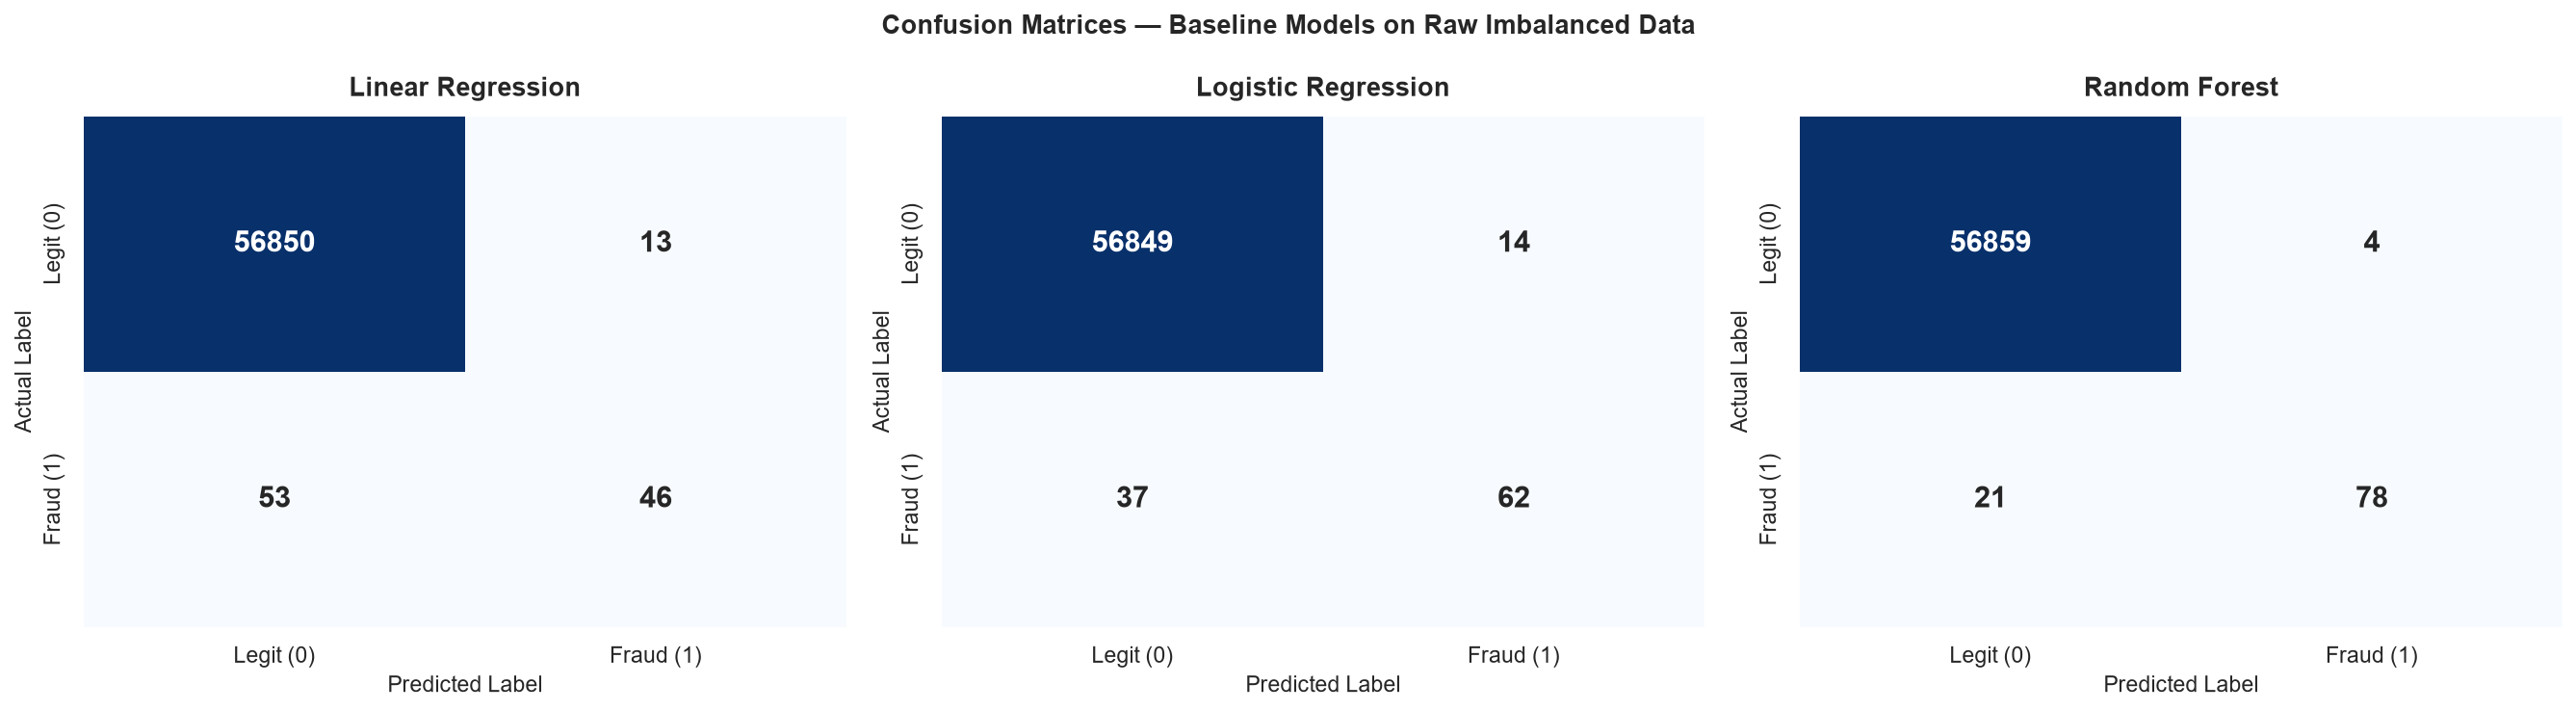

Chart saved -> graphs/b02_confusion_matrices.png


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, m in zip(axes, all_metrics):
    sns.heatmap(
        m['CM'], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
        annot_kws={'size': 15, 'weight': 'bold'}
    )
    ax.set_title(m['Model'], fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('Actual Label', fontsize=11)
    ax.set_xticklabels(['Legit (0)', 'Fraud (1)'])
    ax.set_yticklabels(['Legit (0)', 'Fraud (1)'])

plt.suptitle('Confusion Matrices — Baseline Models on Raw Imbalanced Data', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('graphs/b02_confusion_matrices.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/b02_confusion_matrices.png")

## Cell 10 — ROC Curves Comparison

ROC curves compare models across all possible classification thresholds. A model's AUC summarises
its overall discriminative ability regardless of threshold choice.

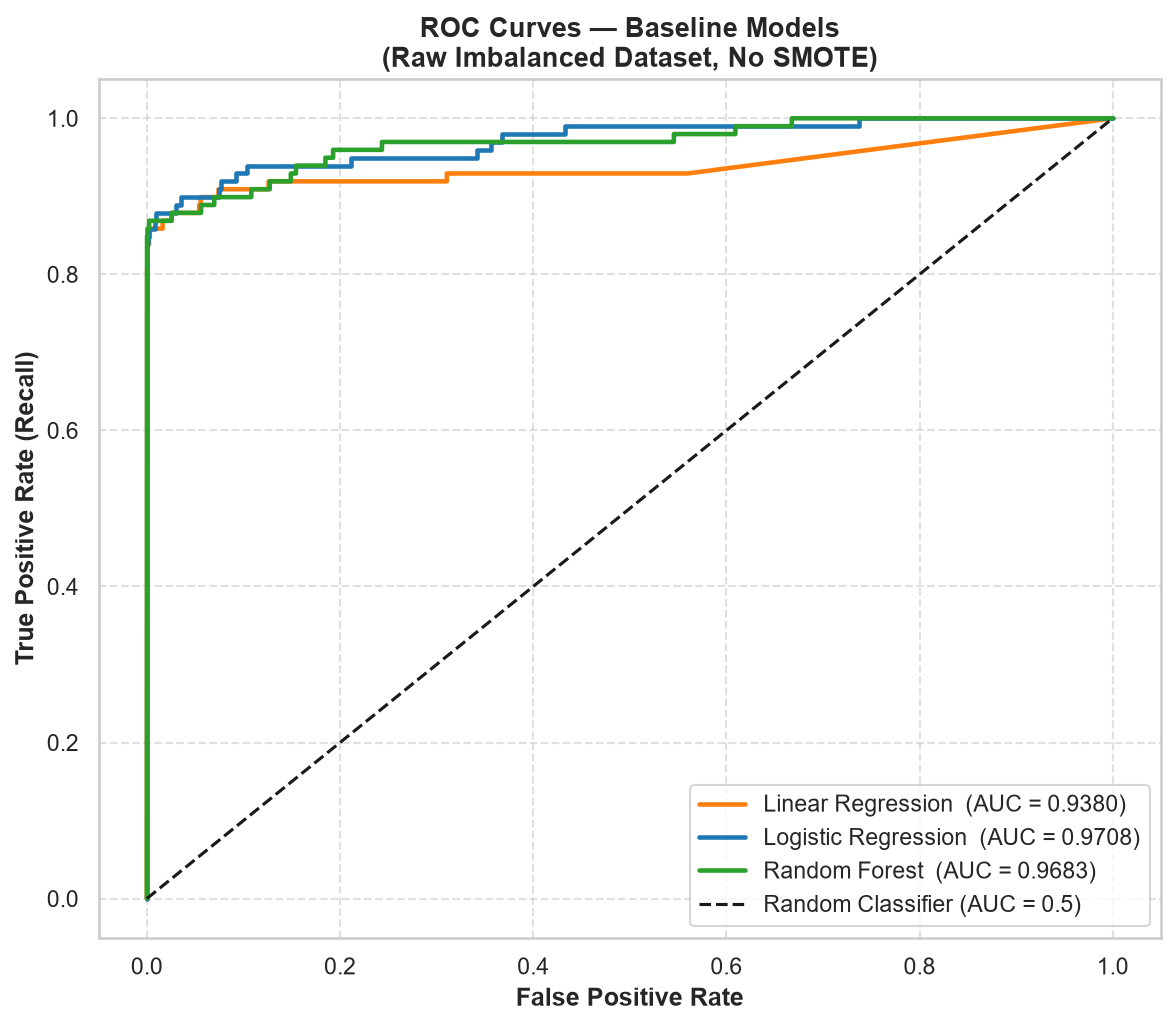

Chart saved -> graphs/b03_roc_curves.png


In [10]:
plt.figure(figsize=(8, 7))

model_probs = [
    (m_lin, y_prob_lin, '#ff7f0e'),
    (m_lr,  y_prob_lr,  '#1f77b4'),
    (m_rf,  y_prob_rf,  '#2ca02c')
]

for m, prob, color in model_probs:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, lw=2.2, color=color,
             label=f"{m['Model']}  (AUC = {float(m['ROC-AUC']):.4f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.5)')
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (Recall)', fontsize=12, fontweight='bold')
plt.title('ROC Curves — Baseline Models\n(Raw Imbalanced Dataset, No SMOTE)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('graphs/b03_roc_curves.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/b03_roc_curves.png")

## Cell 11 — Precision-Recall Curves Comparison

The Precision-Recall curve is the most meaningful evaluation tool for this imbalanced problem.
It shows the trade-off between catching frauds (Recall) and keeping false alarms low (Precision).

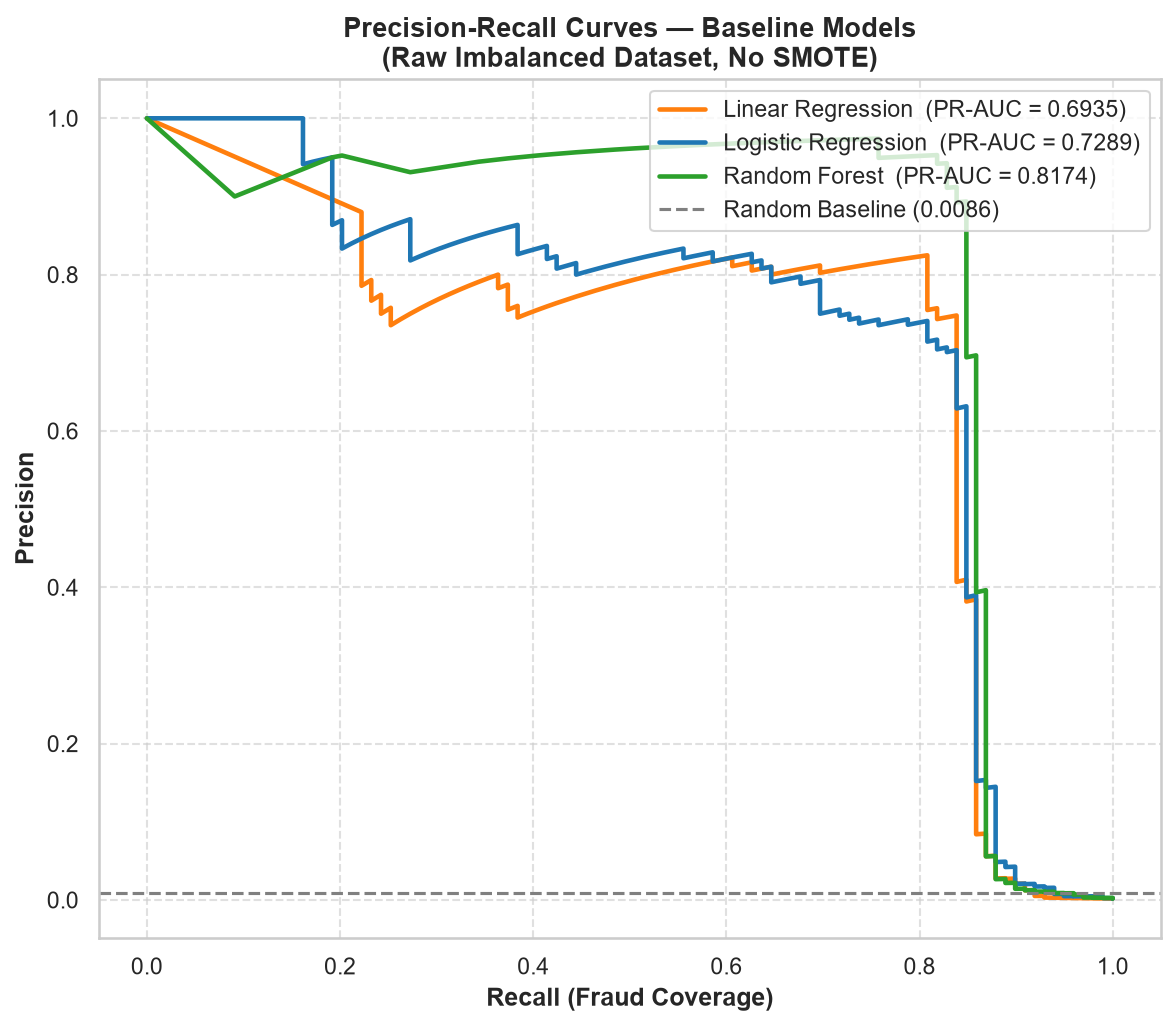

Chart saved -> graphs/b04_pr_curves.png


In [11]:
plt.figure(figsize=(8, 7))

for m, prob, color in model_probs:
    prec_c, rec_c, _ = precision_recall_curve(y_test, prob)
    plt.plot(rec_c, prec_c, lw=2.2, color=color,
             label=f"{m['Model']}  (PR-AUC = {float(m['PR-AUC']):.4f})")

baseline = n_fraud / len(y_test)
plt.axhline(y=baseline, color='gray', linestyle='--', lw=1.5, label=f'Random Baseline ({baseline:.4f})')
plt.xlabel('Recall (Fraud Coverage)', fontsize=12, fontweight='bold')
plt.ylabel('Precision', fontsize=12, fontweight='bold')
plt.title('Precision-Recall Curves — Baseline Models\n(Raw Imbalanced Dataset, No SMOTE)', fontsize=13, fontweight='bold')
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('graphs/b04_pr_curves.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/b04_pr_curves.png")

## Cell 12 — Grouped Metrics Bar Chart

Side-by-side comparison of all key metrics across the three baseline models.

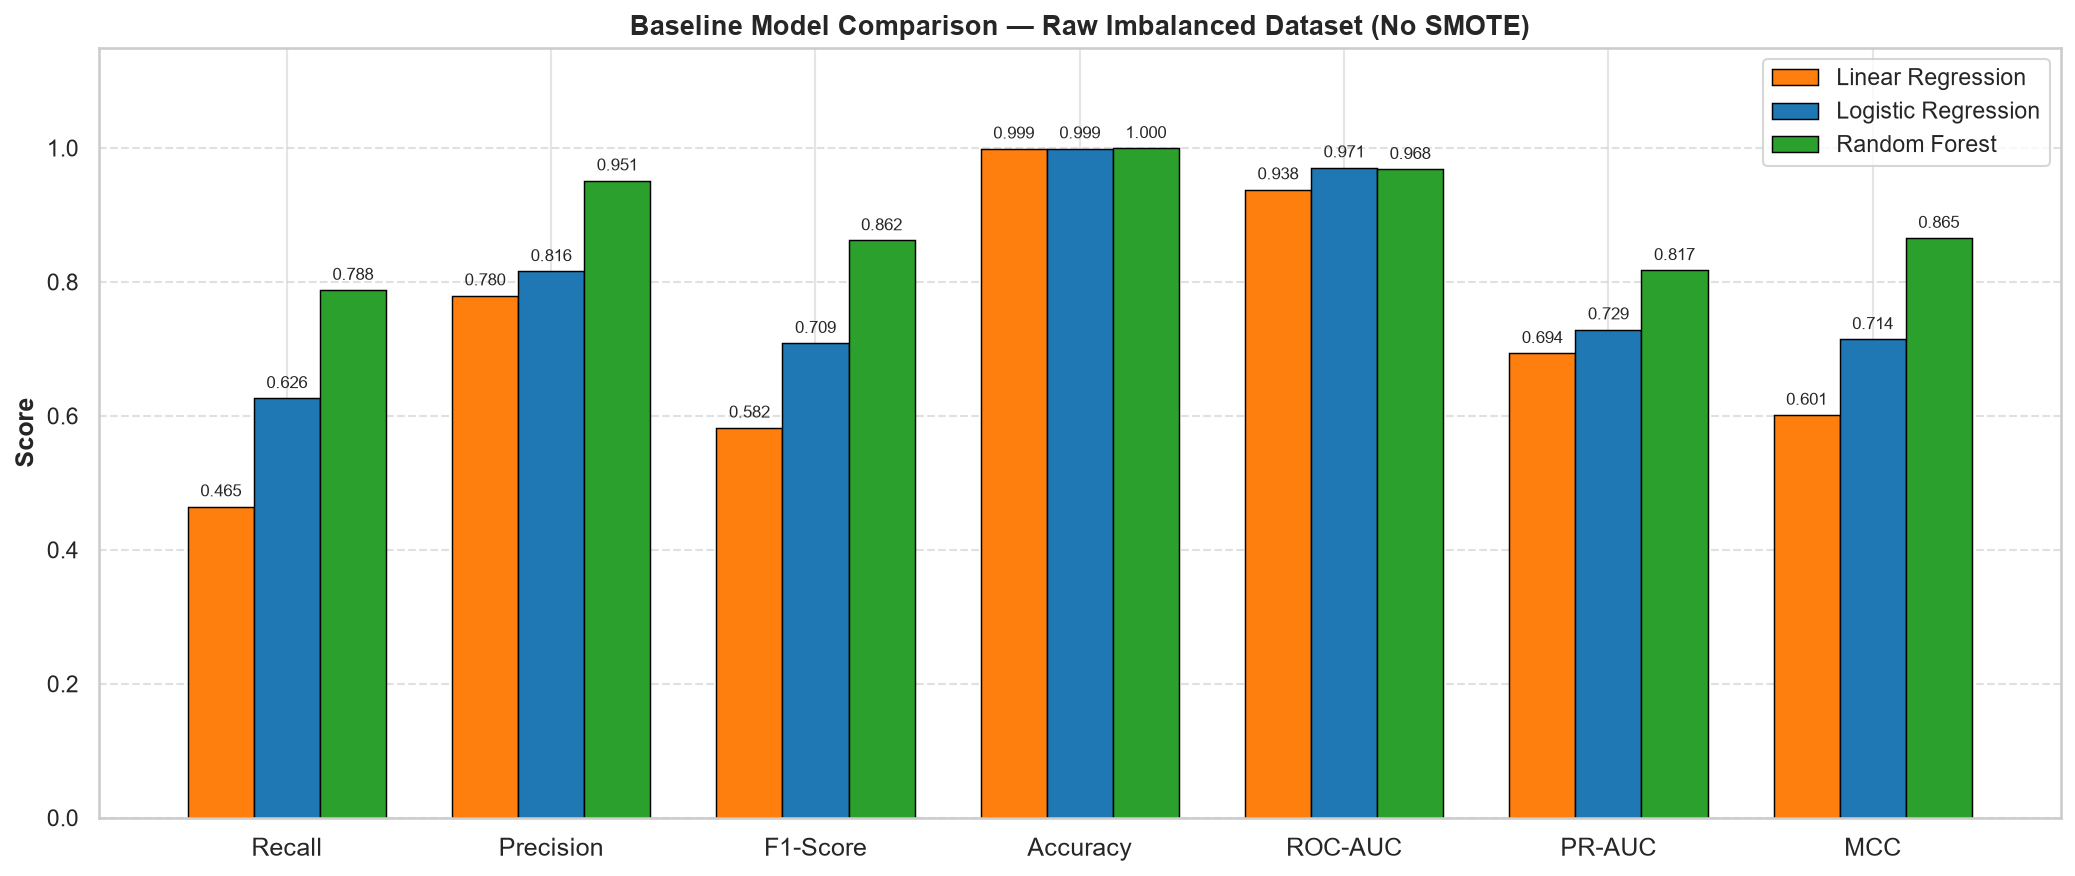

Chart saved -> graphs/b05_metrics_comparison.png


In [12]:
metric_names = ['Recall', 'Precision', 'F1-Score', 'Accuracy', 'ROC-AUC', 'PR-AUC', 'MCC']
vals = {
    'Linear Regression' : [m_lin[m] for m in metric_names],
    'Logistic Regression': [m_lr[m]  for m in metric_names],
    'Random Forest'     : [m_rf[m]  for m in metric_names]
}
colors = ['#ff7f0e', '#1f77b4', '#2ca02c']

x = np.arange(len(metric_names))
w = 0.25
offsets = [-w, 0, w]

fig, ax = plt.subplots(figsize=(14, 6))
for (name, v_list), offset, color in zip(vals.items(), offsets, colors):
    bars = ax.bar(x + offset, v_list, w, label=name, color=color, edgecolor='black', linewidth=0.7)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metric_names, fontsize=12)
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.set_title('Baseline Model Comparison — Raw Imbalanced Dataset (No SMOTE)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('graphs/b05_metrics_comparison.png', bbox_inches='tight')
plt.show()
print("Chart saved -> graphs/b05_metrics_comparison.png")

## Cell 13 — Final Summary Table

In [13]:
print("=" * 90)
print("FINAL BASELINE SUMMARY — Raw Imbalanced Dataset (No SMOTE / No Balancing)")
print("=" * 90)
print(f"{'Metric':<18} {'Linear Regression':>22} {'Logistic Regression':>22} {'Random Forest':>16}")
print("-" * 82)
for col in ['Recall', 'Precision', 'F1-Score', 'Accuracy', 'MCC', 'ROC-AUC', 'PR-AUC']:
    print(f"{col:<18} {m_lin[col]:>22.4f} {m_lr[col]:>22.4f} {m_rf[col]:>16.4f}")
print("-" * 82)
print(f"{'TP (Fraud Caught)':<18} {m_lin['TP']:>22d} {m_lr['TP']:>22d} {m_rf['TP']:>16d}")
print(f"{'FN (Fraud Missed)':<18} {m_lin['FN']:>22d} {m_lr['FN']:>22d} {m_rf['FN']:>16d}")
print(f"{'FP (False Alarms)':<18} {m_lin['FP']:>22d} {m_lr['FP']:>22d} {m_rf['FP']:>16d}")
print(f"{'TN (Legit Cleared)':<18} {m_lin['TN']:>22d} {m_lr['TN']:>22d} {m_rf['TN']:>16d}")
print("=" * 90)
print("\nNote: These baseline results illustrate why SMOTE is critical.")

FINAL BASELINE SUMMARY — Raw Imbalanced Dataset (No SMOTE / No Balancing)
Metric                  Linear Regression    Logistic Regression    Random Forest
----------------------------------------------------------------------------------
Recall                             0.4646                 0.6263           0.7879
Precision                          0.7797                 0.8158           0.9512
F1-Score                           0.5823                 0.7086           0.8619
Accuracy                           0.9988                 0.9991           0.9996
MCC                                0.6014                 0.7143           0.8655
ROC-AUC                            0.9380                 0.9708           0.9683
PR-AUC                             0.6935                 0.7289           0.8174
----------------------------------------------------------------------------------
TP (Fraud Caught)                      46                     62               78
FN (Fraud Missed)     